1. Selection and filtering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import pdfplumber


In [2]:
pdf_path="/home/paragchengappa/programming/UPI-Spending-Analyser/data/raw/bankstats.pdf"
text=""   # called an accumulator, stores all text

with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        page_text=page.extract_text()
        if page_text:
            text+=page_text+ "\n"         
print(text[:2000])


Transaction statement
9019517497, paragchengappa@gmail.com
Transactionstatementperiod Sent Received
01January2026-30June2026 ₹77,368.99 ₹70,536
Date&time Transactiondetails Amount
03Jan,2026 PaidtoJAYARAMAPB ₹30
07:41AM UPITransactionID:600358945338
PaidbyStateBankofIndia7202
03Jan,2026 PaidtoSHIVANNA SHIVANNA ₹231
02:17PM UPITransactionID:636962750553
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoPARASHURAMA ₹56.15
07:29AM UPITransactionID:600553332781
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoRAMESHMR ₹5
09:45AM UPITransactionID:600558105853
PaidbyStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹1,100
01:14PM UPITransactionID:969952655934
PaidtoStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹300
01:19PM UPITransactionID:527376183990
PaidtoStateBankofIndia7202
05Jan,2026 PaidtoBlinkit ₹1,112
01:19PM UPITransactionID:637121529011
PaidbyStateBankofIndia7202
06Jan,2026 PaidtoBMTCBUSKA57F1114 ₹15
12:03PM UPITransactionID:600608819250
PaidbyStateBankofIndia7202
Note:Th

In [3]:
transactions=[]

In [4]:
lines=text.splitlines()

In [5]:
print(lines)

['Transaction statement', '9019517497, paragchengappa@gmail.com', 'Transactionstatementperiod Sent Received', '01January2026-30June2026 ₹77,368.99 ₹70,536', 'Date&time Transactiondetails Amount', '03Jan,2026 PaidtoJAYARAMAPB ₹30', '07:41AM UPITransactionID:600358945338', 'PaidbyStateBankofIndia7202', '03Jan,2026 PaidtoSHIVANNA SHIVANNA ₹231', '02:17PM UPITransactionID:636962750553', 'PaidbyStateBankofIndia7202', '05Jan,2026 PaidtoPARASHURAMA ₹56.15', '07:29AM UPITransactionID:600553332781', 'PaidbyStateBankofIndia7202', '05Jan,2026 PaidtoRAMESHMR ₹5', '09:45AM UPITransactionID:600558105853', 'PaidbyStateBankofIndia7202', '05Jan,2026 ReceivedfromMC NALINAKSHI ₹1,100', '01:14PM UPITransactionID:969952655934', 'PaidtoStateBankofIndia7202', '05Jan,2026 ReceivedfromMC NALINAKSHI ₹300', '01:19PM UPITransactionID:527376183990', 'PaidtoStateBankofIndia7202', '05Jan,2026 PaidtoBlinkit ₹1,112', '01:19PM UPITransactionID:637121529011', 'PaidbyStateBankofIndia7202', '06Jan,2026 PaidtoBMTCBUSKA57F1

In [6]:
import re
i=0

while i<len(lines):
    line=lines[i]

    if re.match(r"\d{2}[A-Za-z]{3,9},\d{4}",line):
        line1=lines[i]
        line2=lines[i+1]
        line3=lines[i+2]

        date=re.search(r"\d{2}[A-Za-z]{3,9},\d{4}",line1).group()

        amount=re.search(r"₹[\d,\.]+",line1).group()

        details=line1.replace(date,"")             #details=string after replacing date w "" from line1
        details=details.replace(amount,"").strip() #details=replace amount from DETAILS w ""
                                                   #strip blank spaces "","" which replaced date and amount
                                                   #and then assign to details

        time=re.search(r"\d{2}:\d{2}[AP]M",line2).group()

        upi=re.search(r"\d{12}",line2).group()
        bank=line3                                 # since in text, third line of each transaction is Paidby/toStateBankOfIndia

        transactions.append([date,time,details,amount,upi,bank])
        i+=3
    else:
        i+=1
                


In [7]:
df=pd.DataFrame(transactions,columns=["Date","Time","Details","Amount","UPI_ID","Bank"])
df.head()

,Date,Time,Details,Amount,UPI_ID,Bank
0,"03Jan,2026",07:41AM,PaidtoJAYARAMAPB,₹30,600358945338,PaidbyStateBankofIndia7202
1,"03Jan,2026",02:17PM,PaidtoSHIVANNA SHIVANNA,₹231,636962750553,PaidbyStateBankofIndia7202
2,"05Jan,2026",07:29AM,PaidtoPARASHURAMA,₹56.15,600553332781,PaidbyStateBankofIndia7202
3,"05Jan,2026",09:45AM,PaidtoRAMESHMR,₹5,600558105853,PaidbyStateBankofIndia7202
4,"05Jan,2026",01:14PM,ReceivedfromMC NALINAKSHI,"₹1,100",969952655934,PaidtoStateBankofIndia7202


In [8]:
df["Date"]=pd.to_datetime(df["Date"],format= "%d%b,%Y")
df["Amount"]=(df["Amount"].str.replace("₹","",regex=False)
              .str.replace(",","",regex=False))
df["Amount"]=df["Amount"].astype(float)
df.info
df.isnull().sum()
df.duplicated().sum()

0

In [9]:
print(df["Details"])

0               PaidtoJAYARAMAPB
1        PaidtoSHIVANNA SHIVANNA
2              PaidtoPARASHURAMA
3                 PaidtoRAMESHMR
4      ReceivedfromMC NALINAKSHI
                 ...            
508            PaidtoAmazonIndia
509    ReceivedfromMC NALINAKSHI
510                 PaidtoMyntra
511    ReceivedfromMC NALINAKSHI
512                PaidtoBlinkit
Name: Details, Length: 513, dtype: object


In [10]:
df["Transaction_Type"]=df["Details"].str.contains(r"Paid",case=False, na=False).map({True:"Paid",
                                                                                     False:"Received"
                                                                                    })

In [11]:
df["Merchant"]= df["Details"].str.replace("Paidto","",regex=False).str.replace("Receivedfrom","",regex=False).str.strip().str.title()
print(df["Merchant"])

0             Jayaramapb
1      Shivanna Shivanna
2            Parashurama
3               Rameshmr
4          Mc Nalinakshi
             ...        
508          Amazonindia
509        Mc Nalinakshi
510               Myntra
511        Mc Nalinakshi
512              Blinkit
Name: Merchant, Length: 513, dtype: object


In [12]:
df["Day"]=df["Date"].dt.day
df["Day_Name"]=df["Date"].dt.day_name()



In [13]:
month_order=["January","February","March","April","May","June","July","August","Spetember","October","November","December"]
df["Month"]=pd.Categorical(df["Date"].dt.month_name(),categories=month_order,ordered=True)
df["Year"]=df["Date"].dt.year

In [14]:
df["Bank"]=(df["Bank"].str.replace("Paidto","",regex=False).str.replace("Paidby","",regex=False).str.strip())

In [15]:
df.head()

,Date,Time,Details,Amount,UPI_ID,Bank,Transaction_Type,Merchant,Day,Day_Name,Month,Year
0,2026-01-03,07:41AM,PaidtoJAYARAMAPB,30.00,600358945338,StateBankofIndia7202,Paid,Jayaramapb,3,Saturday,January,2026
1,2026-01-03,02:17PM,PaidtoSHIVANNA SHIVANNA,231.00,636962750553,StateBankofIndia7202,Paid,Shivanna Shivanna,3,Saturday,January,2026
2,2026-01-05,07:29AM,PaidtoPARASHURAMA,56.15,600553332781,StateBankofIndia7202,Paid,Parashurama,5,Monday,January,2026
3,2026-01-05,09:45AM,PaidtoRAMESHMR,5.00,600558105853,StateBankofIndia7202,Paid,Rameshmr,5,Monday,January,2026
4,2026-01-05,01:14PM,ReceivedfromMC NALINAKSHI,1100.00,969952655934,StateBankofIndia7202,Received,Mc Nalinakshi,5,Monday,January,2026


In [16]:
print(df["Merchant"].unique())

['Jayaramapb' 'Shivanna Shivanna' 'Parashurama' 'Rameshmr' 'Mc Nalinakshi'
 'Blinkit' 'Bmtcbuska57F1114' 'Smartbazaar Bengalurufr47' 'Ka01Ar2969'
 'Mrajeshwaribai' 'Shaik Saleem' 'Sudhakar Chitikela' 'Ganagaraja'
 'Elwineapenm' 'Govindar' 'Aatreyobhattacharya' 'Sadashiva'
 'Veeralchengappa' 'Zepto' 'Ranjancssoshankaregowdat' 'Ka01Ar2872'
 'Swiggy' 'Zeptomarketplaceprivatelimited' 'Ridafathimakhanum'
 'Ka01Ar1160' 'Zeptonow' 'Greentrends' 'Mslifecaremedicals21'
 'Bmtcbuska57F2179' 'Saniya Sultana' 'Soha' 'Mrssaraswathi Ganesan'
 'Lipikasridhar' 'Manjunathahn' 'Mrchennegowda Kc' 'Ssfoodandbeverage'
 'Mrnishanthgowdacm' 'Nagaraja' 'Zabeeralikm' 'Nitikaagarwal'
 'Kishankumar' 'Erannahm' 'Ka51Al6812' 'Mahendrahk' 'Venkateshg'
 'Abhishekr' 'Mr Harshith R' 'Mabu' 'Kumara' 'Spotifyindialip'
 'Manikantas' 'Manjunatha' 'Vigneshvenkatesh' 'Lafemmebeautysaloon'
 'Kavithastores' 'Syedafroz' 'Chaiculture' 'Muskan' 'S Appu'
 'Abhishekshankinamath' 'Bundltechnologiespvtltd' 'Chandrashekhargowda'
 'Aam

- MERCHANT NORMALIZATION

In [17]:
merchant_category={
            "Groceries":{
                "Blinkit":[r"Blinkit"],
                "Swiggy Instamart":[r"Swiggy\s*instamart|Instamart"],
                "Zepto":[r"Zepto"],
                "Supermarkets":[r"Superstore|Smartbazaar|More|Fruits|Vegetables|Farmer, case=False"]
                },
            "Transport":{
                "Transport":[r"Ka{2}/d|Bmtc*|Bmrcl*|Kstrc"]
                },
            "Food":{
                "Swiggy":[r"Swiggy|Bundltechnologiespvtltd"],
                "Zomato":[r"Zomato"],
                "Ownly":[r"Ownly"],
                "MiscFood":[r"Chats|Cafe|Restaurant|Bakes|Food|Beverage|Chai|Coffee|Juice|Bar|Houseofcommonsjpnagar|Thecoral,case=False"]
                },
            "Personal_Transfers":{
                "Elwin":[r"ElwinEapen|ElwinEapenM"],
                "Personal Transfer":[r"Mc nalinakshi|Nalinichengappa|Veeralchengappa|Elwin|Sachins|Nitikaagarwal|Lipikasridhar|Aatreyobhattacharya|Mr harshith r|Aryanbhushan,case=False"]
                },
           "Shopping":{
                "Amazon":[r"Amazon|Amzn"],
                "Flipkart":[r"Flipkart"],
                "Myntra":[r"Myntra"],
                "Nykaa":[r"NykaaFashion|NykaaMakeup|Nykaa"],
                "H&M":[r"HennesandMauritz|HandM|H&M"],
                "SmartBazaar":[r"Justvendprivatelimited"]
            },
            "Salon":{
                "Salon":[r"Beauty|Glamour|Glam|Gorgeous|Salon|Parlour|Spa"],
                "GreenTrends":[r"Greentrends"]
            },
            "Misc":{
                "Recharge":[r"Prepaid|Postpaid"],
                "Stationers":[r"Rameshmr|Mrramesh|Stationers|Bookhouse|Books"],
                "Subsciptions":[r"Spotify|Amazonprime|Netflix|Hotstar"],
                "Online Payments":[r"Amazon pay|Razorpay|Googleplay|Educationpvtltd,case=False"]
            },
}

In [18]:
import re

def assign_category(merchant_name):
    if not isinstance(merchant_name, str):
        return "Other"
    text_lower = merchant_name.lower()

    for category, merchants in merchant_category.items():
        for cleanname, patterns in merchants.items():
            for pattern in patterns:
                if re.search(pattern, text_lower, re.IGNORECASE):
                    return category 
    return "Other"
df["Category"] = df["Merchant"].apply(assign_category)

In [19]:
print(df["Category"].value_counts())

Other                 195
Personal_Transfers    158
Groceries              78
Misc                   33
Food                   23
Transport              13
Shopping                7
Salon                   6
Name: Category, dtype: int64


5. EXPLORATORY DATA ANALYSIS

a. Flow of money

In [20]:
money_flow=df.groupby("Transaction_Type")["Amount"].sum()
money_flow

Transaction_Type
Paid        77368.99
Received    70536.00
Name: Amount, dtype: float64

In [21]:
monthly_flow=df.groupby(["Month","Transaction_Type"],observed=True)["Amount"].sum().unstack(fill_value=0)
monthly_flow

Transaction_Type,Paid,Received
Month,,
January,14027.44,14502.0
February,22120.71,19572.0
March,10446.02,9000.0
April,7140.82,7351.0
May,13462.00,13184.0
June,10172.00,6927.0


b. Spending by Category

In [22]:
category_spending=(df[df["Transaction_Type"]=="Paid"].groupby("Category")["Amount"].sum().sort_values(ascending=False).reset_index())
category_spending

,Category,Amount
0,Groceries,36077.24
1,Other,17542.03
2,Personal_Transfers,8014.00
3,Shopping,7297.00
4,Food,3991.82
5,Salon,2375.90
6,Misc,1456.00
7,Transport,615.00


In [23]:
maxamount=category_spending["Amount"].max()

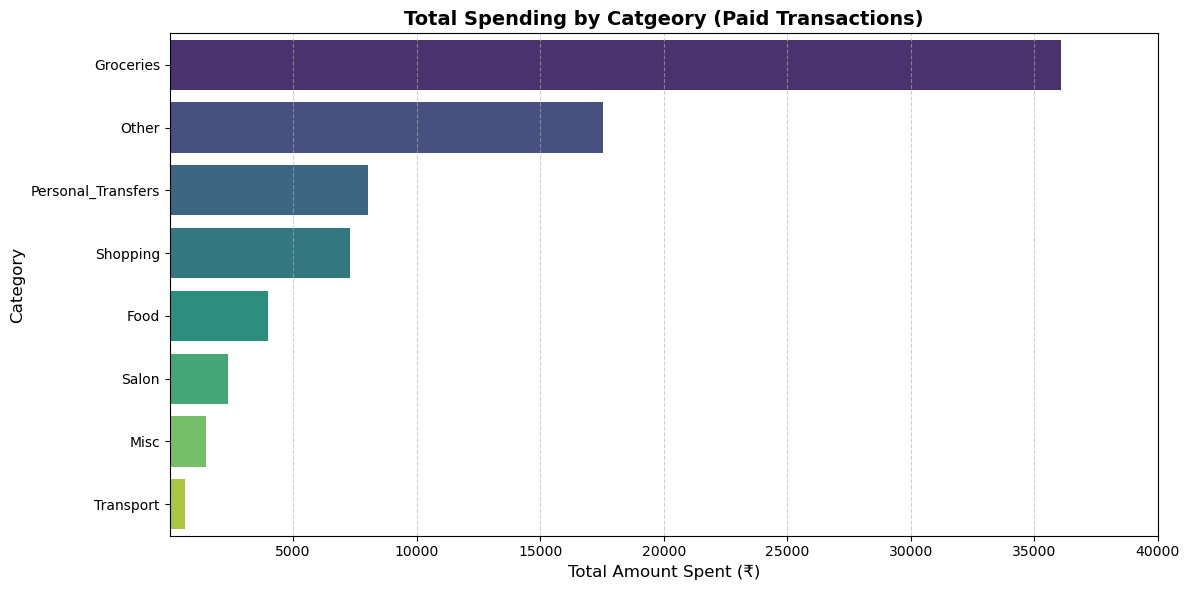

In [24]:
plt.figure(figsize=(12,6))
sns.barplot(
    data=category_spending,
    x="Amount",
    y="Category",
    palette="viridis"
)

x_ticks=np.arange(start=5000,stop=maxamount+5000,step=5000)
plt.xticks(ticks=x_ticks)

plt.title("Total Spending by Catgeory (Paid Transactions)",fontsize=14,fontweight="bold")
plt.xlabel("Total Amount Spent (₹)",fontsize=12)
plt.ylabel("Category",fontsize=12)
plt.grid(axis="x",linestyle="--",alpha=0.6)

plt.tight_layout()
plt.show()

In [25]:
Personal_Spending_Breakdown=df[(df["Category"]=="Personal_Transfers")&(df["Transaction_Type"]=="Paid")]
maxamountpt=Personal_Spending_Breakdown["Amount"].max()

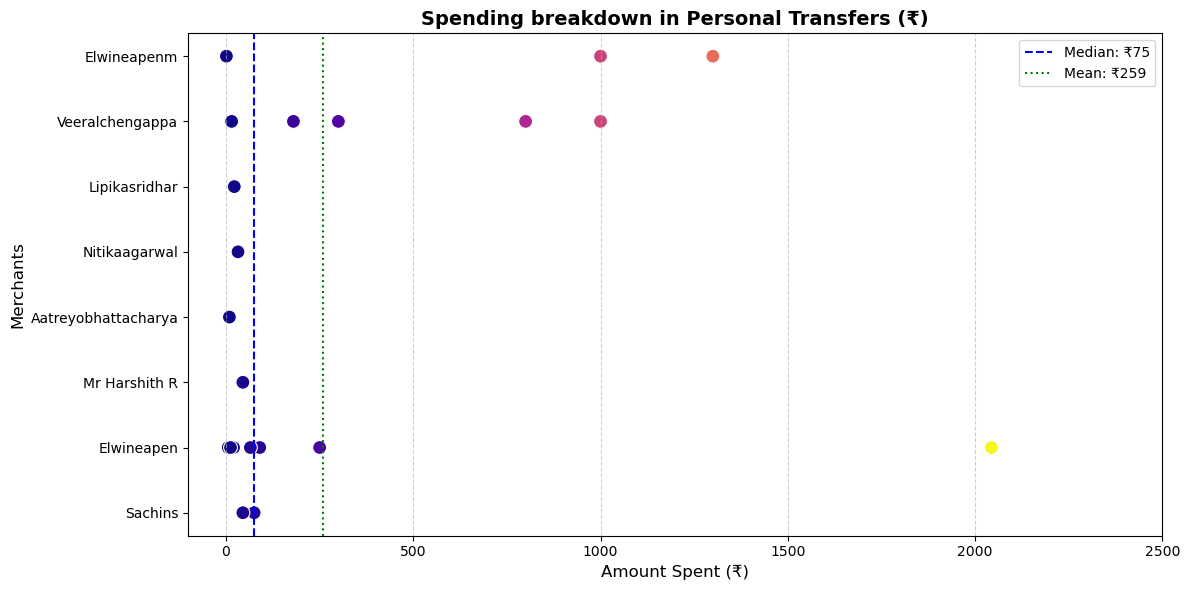

In [26]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    data=Personal_Spending_Breakdown,
    x="Amount",
    y="Merchant",
    hue="Amount",
    palette="plasma",
    s=100,
    legend=False)

plt.xticks(ticks=np.arange(start=0,stop=maxamountpt+500,step=500))
plt.axvline(Personal_Spending_Breakdown["Amount"].median(),color="blue",linestyle="--",label=f"Median: ₹{Personal_Spending_Breakdown['Amount'].median():,.0f}")
plt.axvline(Personal_Spending_Breakdown["Amount"].mean(),color="green",linestyle=":",label=f"Mean: ₹{Personal_Spending_Breakdown['Amount'].mean():,.0f}")
plt.title("Spending breakdown in Personal Transfers (₹)",fontsize=14,fontweight="bold")
plt.xlabel("Amount Spent (₹)",fontsize=12)
plt.ylabel("Merchants",fontsize=12)
plt.grid(axis="x",linestyle="--",alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
category_perc = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Category")["Amount"]
    .sum()
    .reset_index()
    .assign(Percentage=lambda x: (x["Amount"] / x["Amount"].sum()) * 100).round(2)
    .sort_values(by="Percentage", ascending=False)
    .reset_index(drop=True)
)

print(category_perc)

             Category    Amount  Percentage
0           Groceries  36077.24       46.63
1               Other  17542.03       22.67
2  Personal_Transfers   8014.00       10.36
3            Shopping   7297.00        9.43
4                Food   3991.82        5.16
5               Salon   2375.90        3.07
6                Misc   1456.00        1.88
7           Transport    615.00        0.79


In [ ]:
paid_ctg=df[df["Transaction_Type"]=="Paid"].groupby("Category")["Amount"].sum()

color=sns.color_palette("viridis",len(paid_ctg))

plt.figure(figsize=(8,8))
plt.pie(
    paid_ctg,
    labels=paid_ctg.index,
    colors=color,
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Percentage Split of Spending by Category",fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()